# ストリーマ進展に伴う換算電場・化学種密度の軸方向分布

指定した半径位置で、換算電場 [Td] と各化学種の数密度 [m⁻³] の軸方向分布を、同じ時刻の色で並べて描きます。

**Pythonカーネル**で上から順に実行してください。必要なパッケージは `numpy` と `matplotlib` です。
未導入の場合だけ、別セルで `%pip install numpy matplotlib` を実行してください。

- 化学種は係数表モードの `species*.npz` から読み込みます。旧出力は保存されている電子と中性 O のCSVを使います。全8種が必要な場合は、`run_streamer.ipynb` を再実行し、`INPUT_DIR` に新しい出力先を指定します。
- 既定では最も軸に近いセルの **電場の大きさ `|E|/N`** を描きます。`FIELD_MODE` で `|Ez|/N` または符号付き `Ez/N` へ変更できます。
- 半径は指定値に最も近いセル中心を使います。
- 電場CSVは既にTd単位です。再度分子数密度で割る必要はありません。
- 時刻は `times.csv` の実時刻を使います。時刻表がない旧出力ではフレーム番号 × `DT_SECONDS` です。

入力・保存先の相対パスはプロジェクト直下が基準です。

In [1]:
from pathlib import Path
import re

import numpy as np
import matplotlib.pyplot as plt

# ---- 変更する設定 ----
# INPUT_DIR = Path("outputdata_short")
INPUT_DIR = Path("outputdata_photo")  # 保存済みデータのディレクトリ
DT_SECONDS = 1.0e-12               # 計算時のdtに合わせる [s]
TARGET_TIMES_NS = None             # None: 保存済み時刻から最大4本を自動選択
# TARGET_TIMES_NS = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 5.0]  # 保存されている時刻を指定 [ns]
RADIUS_MM = 0.0                    # この半径に最も近いセルを選ぶ [mm]
FIELD_MODE = "magnitude"           # "magnitude", "abs_ez", "ez"
CHEMISTRY_SPECIES = None           # None: 保存済みの全種、例: ("Electron", "O", "O2-"), (): 電場のみ
CHEMISTRY_LOG_SCALE = True         # 正の密度が1桁以上にわたる化学種を対数表示
Z_DISPLAY_SCALE = 4.0              # 図の軸方向座標の倍率。実座標で表示する場合は1.0
Z_LIMITS_MM = None                 # 表示座標での範囲。例: (0.0, 1.0)
FIELD_LIMITS_TD = None             # 例: (0.0, 800.0)
ANNOTATE_PEAKS = False             # 各曲線の最大値を注記（先端位置の判定ではない）
SAVE_RESULTS = True
EXPORT_DIR = Path("figures")
OUTPUT_STEM = "axial_field_profiles"

## 入力データの確認と時刻の選択

`INPUT_DIR` はプロジェクト内の相対パス、または絶対パスで指定します。このNotebookはプロジェクト自身、またはその親フォルダからの実行に対応します。
`TARGET_TIMES_NS` を指定した場合、対応する保存stepがなければエラーとし、別の時刻へ自動置換しません。
標準計算の保存範囲は0〜5 nsです。参考図の15 nsや100 nsを描くには、その時刻までの計算結果が必要です。

In [2]:
# Notebookのフォルダ・プロジェクト直下・親フォルダのどこからでも実行できるようにする。
PROJECT_DIR = next(
    (candidate.resolve()
     for base in (Path.cwd(), *Path.cwd().parents)
     for candidate in (base, base / "pyaxistreamer-master", base / "streamer_python")
     if (candidate / "streamer_drift_diffusion").is_dir()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("streamer_python project not found")
import sys
sys.path.insert(0, str(PROJECT_DIR))
from streamer_drift_diffusion.kinetics import SPECIES_FIELDS
from streamer_drift_diffusion.output import load_output_times
input_dir = INPUT_DIR if INPUT_DIR.is_absolute() else PROJECT_DIR / INPUT_DIR
export_dir = EXPORT_DIR if EXPORT_DIR.is_absolute() else PROJECT_DIR / EXPORT_DIR

field_specs = {
    "magnitude": ("absE", r"$|\mathbf{E}|/N$ [Td]"),
    "abs_ez": ("Ey", r"$|E_z|/N$ [Td]"),
    "ez": ("Ey", r"$E_z/N$ [Td]"),
}
if FIELD_MODE not in field_specs:
    raise ValueError(f"FIELD_MODEは{tuple(field_specs)}から選んでください。")
if not np.isfinite(DT_SECONDS) or DT_SECONDS <= 0:
    raise ValueError("DT_SECONDSは正の有限値にしてください。")
if not np.isfinite(RADIUS_MM) or RADIUS_MM < 0:
    raise ValueError("RADIUS_MMは0以上の有限値にしてください。")
if not np.isfinite(Z_DISPLAY_SCALE) or Z_DISPLAY_SCALE <= 0:
    raise ValueError("Z_DISPLAY_SCALEは正の有限値にしてください。")
if not input_dir.is_dir():
    raise FileNotFoundError(f"CSVフォルダがありません: {input_dir}")
prefix, field_label = field_specs[FIELD_MODE]


def load_coordinate(path):
    values = np.atleast_1d(np.loadtxt(path))
    if values.ndim != 1 or values.size < 2 or not np.all(np.isfinite(values)):
        raise ValueError(f"座標は2点以上の有限値からなる1列にしてください: {path}")
    if np.any(np.diff(values) <= 0):
        raise ValueError(f"座標が昇順ではありません: {path}")
    return values


r_m = load_coordinate(input_dir / "rh.csv")
z_m = load_coordinate(input_dir / "zh.csv")
nr, nz = len(r_m), len(z_m)
r_mm, z_mm = r_m * 1e3, z_m * 1e3
z_display_mm = Z_DISPLAY_SCALE * z_mm
z_label = r"Axial position $z$ [mm]" if Z_DISPLAY_SCALE == 1 else f"Axial position {Z_DISPLAY_SCALE:g}$z$ [mm]"
if RADIUS_MM > r_mm[-1]:
    raise ValueError(f"指定半径がセル中心の最大半径 {r_mm[-1]:g} mm を超えています。")
radial_index = int(np.argmin(np.abs(r_mm - RADIUS_MM)))

pattern = re.compile(rf"^{re.escape(prefix)}(\d+)\.csv$")
available_steps = sorted(
    int(match.group(1))
    for path in input_dir.glob(f"{prefix}*.csv")
    if (match := pattern.fullmatch(path.name))
)
if not available_steps:
    raise FileNotFoundError(f"{input_dir} に {prefix}*.csv がありません。")
available_times_ns = load_output_times(input_dir, available_steps, DT_SECONDS) * 1e9
time_by_frame_ns = dict(zip(available_steps, available_times_ns))

if TARGET_TIMES_NS is None:
    selected_indices = np.unique(
        np.rint(np.linspace(0, len(available_steps) - 1, min(4, len(available_steps)))).astype(int)
    )
    selected_steps = [available_steps[i] for i in selected_indices]
else:
    requested = np.atleast_1d(np.asarray(TARGET_TIMES_NS, dtype=float))
    if requested.ndim != 1 or requested.size == 0 or not np.all(np.isfinite(requested)):
        raise ValueError("TARGET_TIMES_NSには時刻の有限値を1個以上指定してください。")
    selected_steps = []
    for time_ns in requested:
        nearest = int(np.argmin(np.abs(available_times_ns - time_ns)))
        step = available_steps[nearest]
        if not np.isclose(available_times_ns[nearest], time_ns, rtol=1e-9, atol=1e-9):
            nearest = int(np.argmin(np.abs(available_times_ns - time_ns)))
            raise ValueError(
                f"t={time_ns:g} nsのCSVがありません。最も近い保存時刻は "
                f"{available_times_ns[nearest]:g} ns (step {available_steps[nearest]})。"
                "TARGET_TIMES_NSまたはDT_SECONDSを確認してください。"
            )
        selected_steps.append(step)
    selected_steps = sorted(set(selected_steps))

print(f"Input: {input_dir}")
print(f"Grid: nr={nr}, nz={nz}")
print(f"Selected radius: r={r_mm[radial_index]:.6g} mm (index {radial_index})")
print(f"Available: {available_times_ns[0]:g}–{available_times_ns[-1]:g} ns, {len(available_steps)} frames")
print("Selected times [ns]:", [time_by_frame_ns[step] for step in selected_steps])
if len(selected_steps) == 1:
    print("1時刻のみです。進展の比較には追加stepのCSVが必要です。")

Input: C:\Users\daiko\Documents\Python_venvSystem\3.14system\PyAxiStreamer\pyaxistreamer-master\outputdata_photo
Grid: nr=400, nz=300
Selected radius: r=0.0025 mm (index 0)
Available: 0–1.5 ns, 16 frames
Selected times [ns]: [np.float64(0.0), np.float64(0.5), np.float64(1.0), np.float64(1.5)]


## 軸方向プロファイルの読み込み

CSVはC互換の `for(i) for(j)` 順なので、`reshape((nr, nz), order="C")` で `(r, z)` 配列に復元し、選んだ半径の1行を取り出します。
選択した半径のNaN・無限大は欠損値として扱い、その位置で線を途切れさせます。欠損区間の補間は行いません。その半径の値がすべて非有限値の時刻はスキップし、最大値は有限値のみから求めます。選択した全時刻に有限値がなければ、説明付きのエラーにします。行数が足りないなど不完全なファイルは引き続きエラーにします。計算が書き込み中の場合は、完了後に再実行してください。

In [3]:
def read_csv_grid(path):
    """1列の保存データをセル中心の格子に戻す。

    Parameters
    ----------
    path : pathlib.Path
        格子順に1値ずつ並ぶ出力CSV。

    Returns
    -------
    ndarray, shape (nr, nz)
        r、zの順に並ぶセル中心値。

    Examples
    --------
    電子密度の初期フレームを読む::

        density = read_csv_grid(input_dir / 'ne0.csv')
    """
    values = np.atleast_1d(np.loadtxt(path))
    if values.ndim != 1 or values.size != nr * nz:
        raise ValueError(
            f"{path.name}: 1列{nr * nz}値を期待しましたがshape={values.shape}です。"
            "書き込み途中または異なる格子の出力が混在していないか確認してください。"
        )
    return values.reshape((nr, nz), order="C")


def read_profile(step):
    path = input_dir / f"{prefix}{step}.csv"
    profile = read_csv_grid(path)[radial_index, :].copy()
    finite = np.isfinite(profile)
    if not finite.any():
        print(f"Skipping {path.name}: 選択した半径に有限値がありません。")
        return None
    if not finite.all():
        print(f"{path.name}: 選択した半径の非有限値 {(~finite).sum()} 点を欠損として描画します。")
        profile[~finite] = np.nan  # NaNの位置で線を切り、欠損区間を結ばない
    return np.abs(profile) if FIELD_MODE == "abs_ez" else profile


profiles = {}
for step in selected_steps:
    profile = read_profile(step)
    if profile is not None:
        profiles[step] = profile
if not profiles:
    raise ValueError("選択した半径・時刻に有限値がありません。半径または時刻を変更してください。")
print("step    time [ns]    max field [Td]    z at maximum [mm]")
for step, profile in profiles.items():
    peak = int(np.nanargmax(profile))
    print(f"{step:5d}    {time_by_frame_ns[step]:9.4f}    {profile[peak]:14.4f}    {z_mm[peak]:17.6f}")

step    time [ns]    max field [Td]    z at maximum [mm]
    0       0.0000           31.1856             0.997500
    5       0.5000          250.3172             0.732500
   10       1.0000          581.6668             0.627500
   15       1.5000         1100.3410             0.067500


## 同じフレームの化学種密度を抽出

電場と同じ半径・軸方向位置の数密度を取り出します。`gas_mask.csv` がある場合は電極セルを除きます。
対数軸ではゼロの区間で線が切れます。密度の変化が小さい化学種は線形軸で表示します。

In [4]:
species_names = tuple(SPECIES_FIELDS if CHEMISTRY_SPECIES is None else CHEMISTRY_SPECIES)
unknown_species = set(species_names) - SPECIES_FIELDS.keys()
if unknown_species:
    raise ValueError(f"未知の化学種 {sorted(unknown_species)}。{tuple(SPECIES_FIELDS)} から選んでください。")

density_profiles = {species: {} for species in species_names}
if density_profiles:
    mask_path = input_dir / "gas_mask.csv"
    gas_row = (read_csv_grid(mask_path)[radial_index] == 1
               if mask_path.is_file() else np.ones(nz, dtype=bool))
    legacy_prefix = {"Electron": "ne", "O": "O"}
    for step in profiles:
        archive_path = input_dir / f"species{step}.npz"
        if archive_path.is_file():
            with np.load(archive_path, allow_pickle=False) as archive:
                grids = {species: archive[species] for species in density_profiles if species in archive}
        else:
            grids = {}
            for species, csv_prefix in legacy_prefix.items():
                path = input_dir / f"{csv_prefix}{step}.csv"
                if species in density_profiles and path.is_file():
                    grids[species] = read_csv_grid(path)
        for species, grid in grids.items():
            if grid.shape != (nr, nz):
                raise ValueError(f"フレーム {step} の {species} の密度配列に格子と異なる形状 {grid.shape} が含まれます。")
            density_profiles[species][step] = np.where(gas_row, grid[radial_index], np.nan)
    for species, by_frame in density_profiles.items():
        missing = profiles.keys() - by_frame.keys()
        if missing:
            print(f"{species} の密度が未保存のフレーム: {sorted(missing)}")
    density_profiles = {species: by_frame for species, by_frame in density_profiles.items() if by_frame}


## 複数時刻の曲線を重ねて描画

電場と化学種密度の全パネルで時刻の色と横軸を揃えます。電極付近の電界も含むため、曲線の最大位置が必ずストリーマ先端とは限りません。
進展方向は曲線と座標から読み取ってください。参考図の右向き矢印は、本計算の進展方向として仮定していません。

Saved: C:\Users\daiko\Documents\Python_venvSystem\3.14system\PyAxiStreamer\pyaxistreamer-master\figures\axial_field_profiles_magnitude.png
Saved: C:\Users\daiko\Documents\Python_venvSystem\3.14system\PyAxiStreamer\pyaxistreamer-master\figures\axial_field_profiles_magnitude.pdf


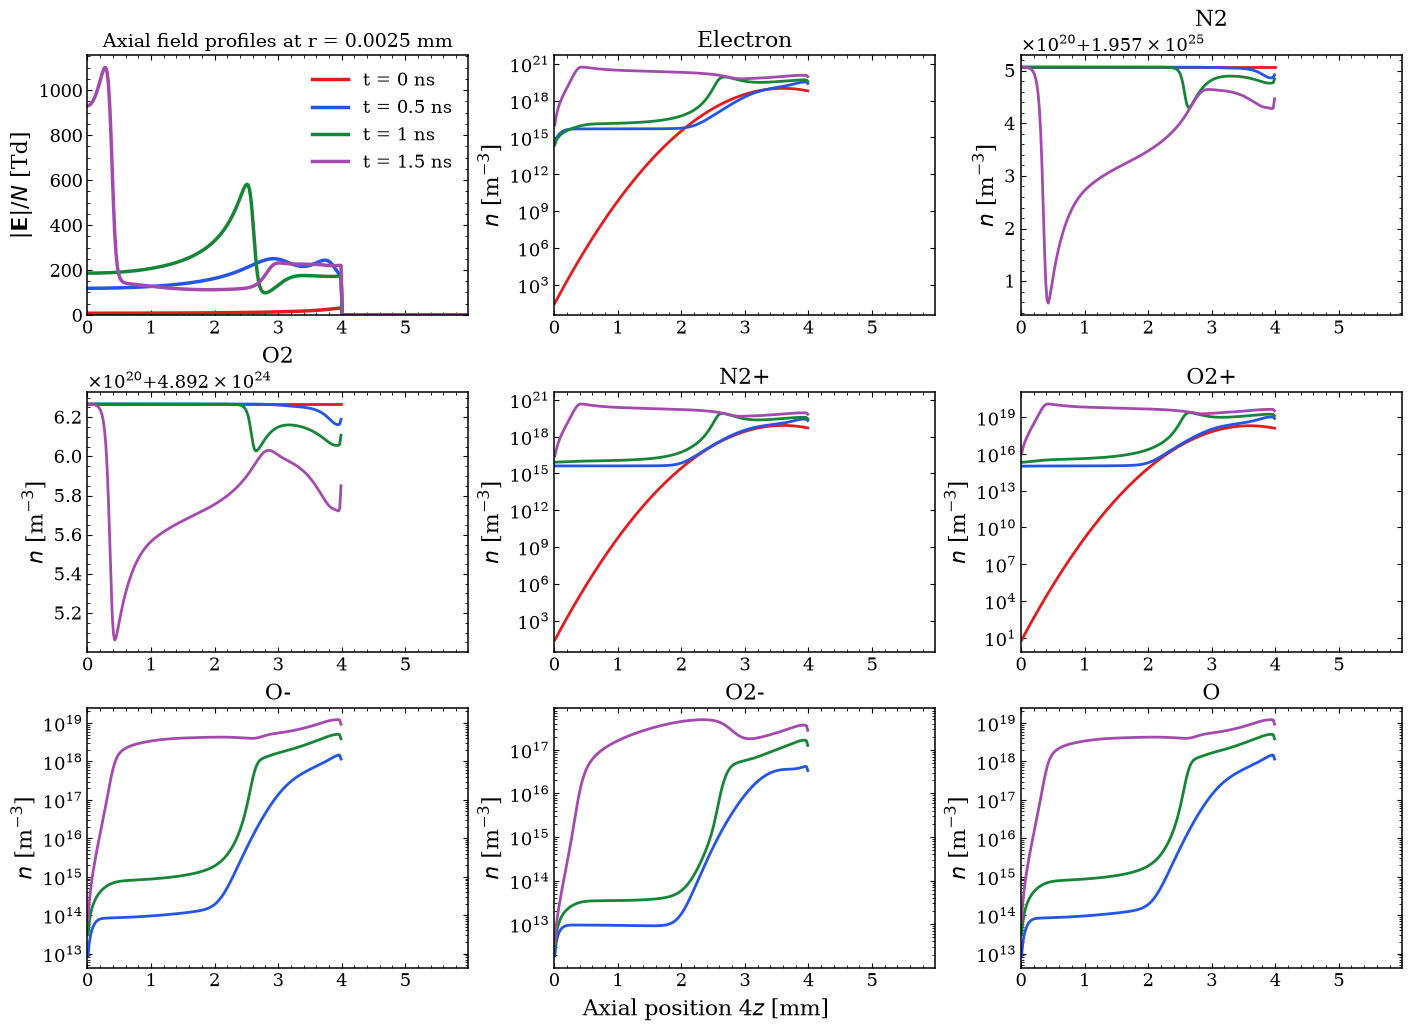

In [5]:
colors = ["#e41a1c", "#2455e6", "#168537", "#a24bad", "#e88812", "#168d9b"]
frame_colors = {step: colors[i % len(colors)] for i, step in enumerate(profiles)}
panel_count = 1 + len(density_profiles)
ncols = 1 if panel_count <= 3 else 3
nrows = (panel_count + ncols - 1) // ncols
with plt.rc_context({
    "font.family": "serif",
    "font.size": 13,
    "axes.labelsize": 16,
    "axes.linewidth": 1.1,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "pdf.fonttype": 42,
}):
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(8.5 if ncols == 1 else 14, 5.5 if nrows == 1 else 3.4 * nrows),
        sharex=True, squeeze=False, layout="constrained",
    )
    ax = axes.flat[0]
    for index, (step, profile) in enumerate(profiles.items()):
        time_ns = time_by_frame_ns[step]
        color = frame_colors[step]
        ax.plot(z_display_mm, profile, color=color, linewidth=2.5, label=f"t = {time_ns:g} ns")
        if ANNOTATE_PEAKS:
            peak = int(np.nanargmax(profile))
            ax.plot(z_display_mm[peak], profile[peak], "o", color=color, markersize=4)
            ax.annotate(
                f"{time_ns:g} ns", xy=(z_display_mm[peak], profile[peak]),
                xytext=(7, -15 - 15 * (index % 2)), textcoords="offset points",
                color=color, fontsize=11,
            )
    ax.set_ylabel(field_label)
    ax.set_title(f"Axial field profiles at r = {r_mm[radial_index]:g} mm", fontsize=14)
    ax.set_xlim(Z_LIMITS_MM if Z_LIMITS_MM is not None else (0, z_display_mm[-1]))
    if FIELD_LIMITS_TD is not None:
        ax.set_ylim(FIELD_LIMITS_TD)
    elif FIELD_MODE != "ez":
        ax.set_ylim(bottom=0)
    ax.legend(frameon=False, loc="best")
    for panel, (species, by_frame) in zip(axes.flat[1:], density_profiles.items()):
        positive = np.concatenate([values[values > 0] for values in by_frame.values()])
        logarithmic = CHEMISTRY_LOG_SCALE and positive.size > 0 and positive.min() <= positive.max() / 10
        if logarithmic:
            panel.set_yscale("log", nonpositive="mask")
        else:
            panel.ticklabel_format(axis="y", style="sci", scilimits=(-3, 3), useMathText=True)
        for step, density in by_frame.items():
            values = np.where(density > 0, density, np.nan) if logarithmic else density
            panel.plot(z_display_mm, values, color=frame_colors[step], linewidth=2.0)
        panel.set(title=species, ylabel=r"$n$ [m$^{-3}$]")
    for panel in axes.flat[:panel_count]:
        panel.tick_params(which="both", top=True, right=True, labelbottom=True)
        panel.minorticks_on()
    for panel in axes.flat[panel_count:]:
        panel.set_visible(False)
    if density_profiles:
        fig.supxlabel(z_label)
    else:
        ax.set_xlabel(z_label)
    if SAVE_RESULTS:
        export_dir.mkdir(parents=True, exist_ok=True)
        for extension in ("png", "pdf"):
            destination = export_dir / f"{OUTPUT_STEM}_{FIELD_MODE}.{extension}"
            fig.savefig(destination, dpi=200, bbox_inches="tight")
            print(f"Saved: {destination}")
    plt.show()

## 抽出した数値の保存

保存を有効にすると、画像に加えて、実座標 z [mm] と各時刻の電界・化学種密度を複数列CSVへ保存します。図で使う座標倍率はCSVヘッダーに記録します。
同名の画像・抽出CSVは再実行時に上書きされます。元のシミュレーションCSVは読み取りだけ行います。
欠損位置は抽出CSVにも `nan` として保存し、全点が欠損でスキップした時刻は列に含めません。

In [6]:
if SAVE_RESULTS:
    data = [z_mm, *profiles.values()]
    columns = ["z_mm"] + [f"{FIELD_MODE}_Td_step{step}" for step in profiles]
    missing_density = np.full(nz, np.nan)
    for species, by_frame in density_profiles.items():
        for step in profiles:
            data.append(by_frame.get(step, missing_density))
            columns.append(f"n_{species}_m-3_step{step}")
    table = np.column_stack(data)
    metadata = (
        f"radius_mm={r_mm[radial_index]:.12g}; dt_seconds={DT_SECONDS:.12g}; "
        f"z_display_scale={Z_DISPLAY_SCALE:g}; "
        "time_label_ns=times.csv_when_present; "
        + "; ".join(f"step{step}_time_ns={time_by_frame_ns[step]:g}" for step in profiles)
    )
    destination = export_dir / f"{OUTPUT_STEM}_{FIELD_MODE}.csv"
    np.savetxt(destination, table, delimiter=",", header=metadata + "\n" + ",".join(columns))
    print(f"Saved: {destination}")
else:
    print("SAVE_RESULTS=False: ファイル保存は無効です。")

Saved: C:\Users\daiko\Documents\Python_venvSystem\3.14system\PyAxiStreamer\pyaxistreamer-master\figures\axial_field_profiles_magnitude.csv
